# A network in Keras, on handwritten digits

Notebook 01 used scikit-learn's `MLPClassifier`, which hides the network
inside one object. Keras, the library this notebook and lesson 10 use, makes
each part visible: you list the layers, choose how to measure the error, and
watch training happen epoch by epoch.

The problem is real this time: the 8×8 handwritten digits that ship with
scikit-learn, ten classes. By the end you will have built, trained and read a
network layer by layer, seen how **softmax** turns ten scores into ten
probabilities, and measured how much the hidden layer is worth here, against
the 39 points it was worth on the sensors.

## 1. Setup

In [1]:
# pip install numpy==1.26.4 pandas==2.1.1 matplotlib==3.8.0 scikit-learn==1.3.1 tensorflow-cpu==2.21.0

import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"     # keep TensorFlow's C++ log quiet

import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf
import keras
from keras import layers

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler

from instrument_data import load_digit_images, make_acceptance_test, TRUE_N_CLASSES

# MLPClassifier warns when it stops at max_iter; the runs below are long enough.
warnings.filterwarnings("ignore", message="Stochastic Optimizer")
FIGURES = Path.cwd().parent / "Figures"
FIGURES.mkdir(exist_ok=True)
BLUE, TEAL, RUST, GOLD, SLATE = "#1F4E79", "#2E8B8B", "#B4483E", "#C9A227", "#4A5568"

# Two settings make a run reproducible: the seed fixes the starting weights and
# the shuffling, and op determinism fixes the order of floating-point sums.
tf.config.experimental.enable_op_determinism()
print("tensorflow", tf.__version__, " keras", keras.__version__)

I0000 00:00:1792198941.632916  854187 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1792198942.697895  854187 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


tensorflow 2.21.0  keras 3.15.1


## 2. The digits

Each image is 8×8 = 64 pixels, scaled to lie between 0 and 1. The data is
split three ways (lesson 5): train to fit, validation to compare designs,
test touched once at the end.

train (1077, 64)   validation (360, 64)   test (360, 64)


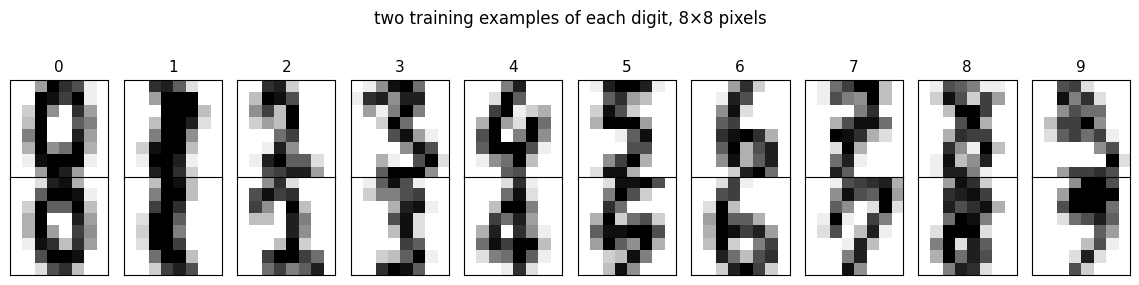

In [2]:
X_tr, y_tr, X_va, y_va, X_te, y_te = load_digit_images()
print(f"train {X_tr.shape}   validation {X_va.shape}   test {X_te.shape}")

fig, axes = plt.subplots(2, 10, figsize=(11.5, 2.7))
for k in range(TRUE_N_CLASSES):
    for row, index in enumerate(np.where(y_tr == k)[0][:2]):
        ax = axes[row, k]
        ax.imshow(X_tr[index].reshape(8, 8), cmap="gray_r", vmin=0, vmax=1)
        ax.set_xticks([]); ax.set_yticks([])
        if row == 0:
            ax.set_title(str(k), fontsize=11)
fig.suptitle("two training examples of each digit, 8×8 pixels", y=1.04)
fig.tight_layout()
fig.savefig(FIGURES / "digit_examples.png", dpi=150, bbox_inches="tight")
plt.show()

## 3. Building the network, layer by layer

Three lines describe the whole network: 64 inputs, one hidden layer of 32
ReLU units, and an output layer of 10 units, one per digit, with **softmax**.

In [3]:
keras.utils.set_random_seed(0)
model = keras.Sequential([
    keras.Input(shape=(64,)),                      # 64 pixels in
    layers.Dense(32, activation="relu"),           # hidden layer: 32 units
    layers.Dense(10, activation="softmax"),        # output: 10 probabilities
])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           330 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,410 (9.41 KB)

 Trainable params: 2,410 (9.41 KB)

 Non-trainable params: 0 (0.00 B)

The parameter count is worth checking by hand once. The hidden layer has one
weight per (pixel, unit) pair plus one bias per unit: $64 \times 32 + 32 = 2{,}080$.
The output layer: $32 \times 10 + 10 = 330$. Total 2,410.

`compile` says how to measure the error and how to reduce it: the loss is
**cross-entropy**, lesson 4's log-loss extended to ten classes, and the
optimiser is **Adam**, a refined form of gradient descent. `fit` then trains:
each **epoch** is one pass through the 1,077 training images, taken in
**mini-batches** of 32, with one gradient step per mini-batch.

In [4]:
model.compile(optimizer=keras.optimizers.Adam(1e-3),
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])
history = model.fit(X_tr, y_tr, validation_data=(X_va, y_va),
                    epochs=60, batch_size=32, verbose=0).history

steps = int(np.ceil(len(X_tr) / 32))
print(f"{steps} mini-batches per epoch, so {60 * steps:,} gradient steps in 60 epochs")
print(f"after epoch  1: training accuracy {history['accuracy'][0]:.4f}, "
      f"validation {history['val_accuracy'][0]:.4f}")
print(f"after epoch 60: training accuracy {history['accuracy'][-1]:.4f}, "
      f"validation {history['val_accuracy'][-1]:.4f}")

34 mini-batches per epoch, so 2,040 gradient steps in 60 epochs
after epoch  1: training accuracy 0.1374, validation 0.2667
after epoch 60: training accuracy 0.9926, validation 0.9639


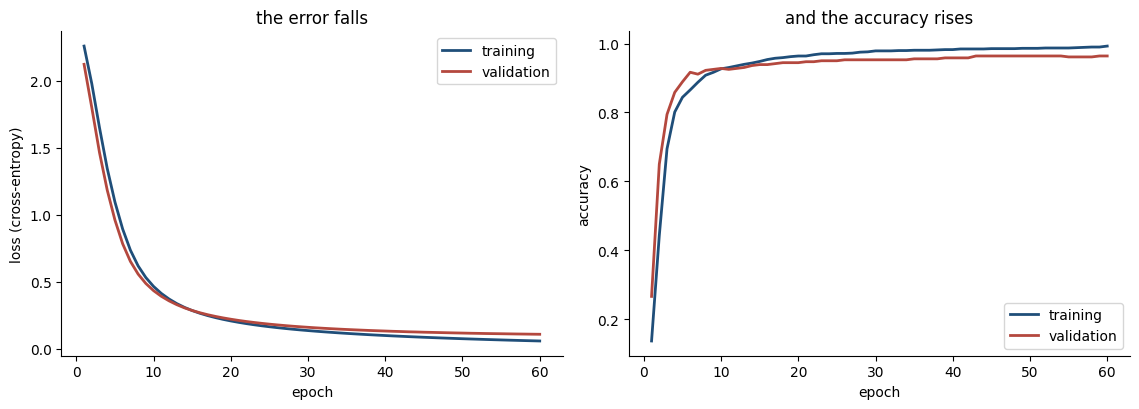

In [5]:
epochs = np.arange(1, 61)
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.2))
axes[0].plot(epochs, history["loss"], color=BLUE, lw=2, label="training")
axes[0].plot(epochs, history["val_loss"], color=RUST, lw=2, label="validation")
axes[0].set_ylabel("loss (cross-entropy)"); axes[0].set_title("the error falls")
axes[1].plot(epochs, history["accuracy"], color=BLUE, lw=2, label="training")
axes[1].plot(epochs, history["val_accuracy"], color=RUST, lw=2, label="validation")
axes[1].set_ylabel("accuracy"); axes[1].set_title("and the accuracy rises")
for ax in axes:
    ax.set_xlabel("epoch"); ax.legend()
    ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(FIGURES / "training_curves.png", dpi=150, bbox_inches="tight")
plt.show()

Most of the learning happens in the first few epochs; after that both curves
creep. The training curve ends above the validation curve, as it always will:
the network has seen those images. Notebook 03 is about what to do when that
gap grows.

## 4. Softmax: ten scores become ten probabilities

The output layer computes ten numbers for each image, one per digit. Softmax
makes them positive and makes them add up to 1, so they can be read as
probabilities: $\mathrm{softmax}(z)_k = e^{z_k} / \sum_j e^{z_j}$. The
prediction is the digit with the largest one.

each row sums to 1: smallest sum 1.000000, largest 1.000000
image 0: true 6; most probable 6 (0.991), then 8 (0.008)
image 115: true 1; most probable 4 (0.323), then 8 (0.241)


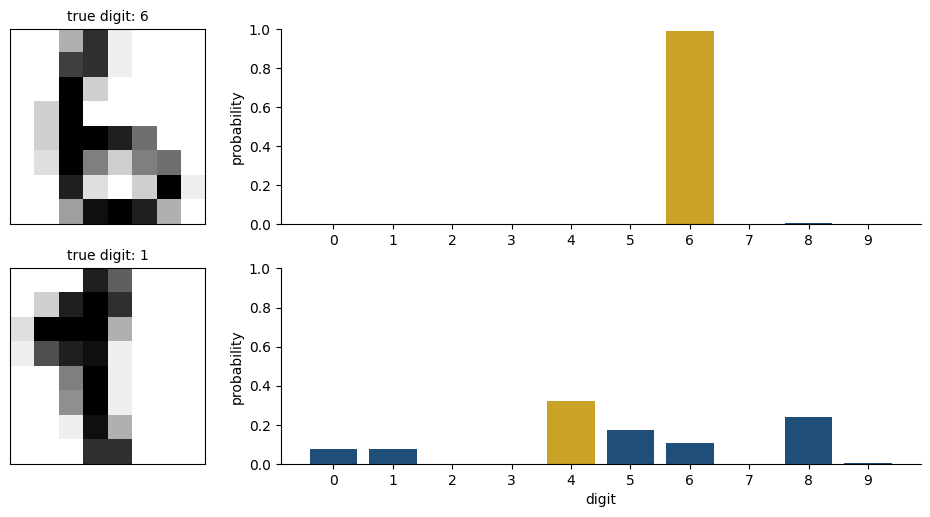


the most confident mistake: image 87, a 4 called a 7 with probability 0.920


In [6]:
probabilities = model.predict(X_va, verbose=0)
print(f"each row sums to 1: smallest sum {probabilities.sum(axis=1).min():.6f}, "
      f"largest {probabilities.sum(axis=1).max():.6f}")

wrong = np.where(probabilities.argmax(axis=1) != y_va)[0]
top = probabilities.max(axis=1)
least_sure = wrong[np.argmin(top[wrong])]   # the mistake made with least confidence
most_sure = wrong[np.argmax(top[wrong])]    # the mistake made with most confidence
examples = [0, least_sure]                  # one ordinary image, one hesitant mistake
fig, axes = plt.subplots(2, 2, figsize=(9.5, 5.2),
                         gridspec_kw={"width_ratios": [1, 3]})
for row, index in enumerate(examples):
    axes[row, 0].imshow(X_va[index].reshape(8, 8), cmap="gray_r", vmin=0, vmax=1)
    axes[row, 0].set_xticks([]); axes[row, 0].set_yticks([])
    axes[row, 0].set_title(f"true digit: {y_va[index]}", fontsize=10)
    colours = [GOLD if k == probabilities[index].argmax() else BLUE for k in range(10)]
    axes[row, 1].bar(range(10), probabilities[index], color=colours)
    axes[row, 1].set_xticks(range(10)); axes[row, 1].set_ylim(0, 1)
    axes[row, 1].set_ylabel("probability")
    axes[row, 1].spines[["top", "right"]].set_visible(False)
    first, second = np.argsort(probabilities[index])[::-1][:2]
    print(f"image {index}: true {y_va[index]}; most probable {first} "
          f"({probabilities[index][first]:.3f}), then {second} "
          f"({probabilities[index][second]:.3f})")
axes[1, 1].set_xlabel("digit")
fig.tight_layout()
fig.savefig(FIGURES / "softmax_example.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"\nthe most confident mistake: image {most_sure}, a {y_va[most_sure]} called a "
      f"{probabilities[most_sure].argmax()} with probability {top[most_sure]:.3f}")

The first image is easy: nearly all the probability sits on one digit. The
second is the mistake the network was least sure about: no digit gets even a
third of the probability, a hesitation a bare label would hide. But a probability
is not a guarantee: the last line printed is a mistake made with high confidence.
Softmax says how sure the network is, not how right it is.

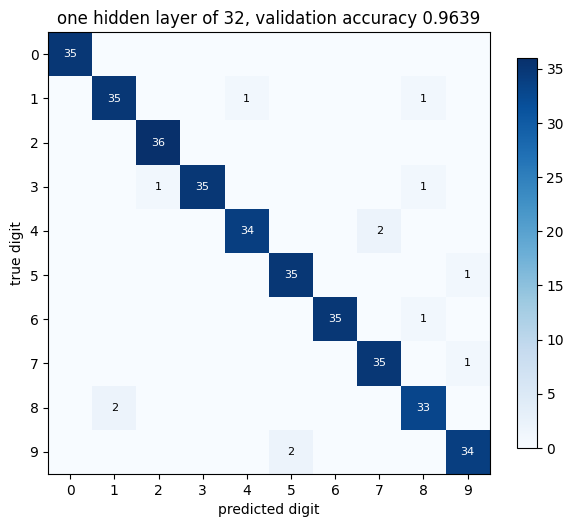

13 of 360 validation images wrong


In [7]:
predicted = probabilities.argmax(axis=1)
matrix = confusion_matrix(y_va, predicted)
fig, ax = plt.subplots(figsize=(6.2, 5.4))
image = ax.imshow(matrix, cmap="Blues")
for i in range(TRUE_N_CLASSES):
    for j in range(TRUE_N_CLASSES):
        if matrix[i, j]:
            ax.text(j, i, matrix[i, j], ha="center", va="center", fontsize=8,
                    color="white" if matrix[i, j] > matrix.max() * .6 else "black")
ax.set_xticks(range(10)); ax.set_yticks(range(10))
ax.set_xlabel("predicted digit"); ax.set_ylabel("true digit")
ax.set_title(f"one hidden layer of 32, validation accuracy {(predicted == y_va).mean():.4f}")
fig.colorbar(image, ax=ax, shrink=.82)
fig.tight_layout()
fig.savefig(FIGURES / "softmax_confusion.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"{(predicted != y_va).sum()} of {len(y_va)} validation images wrong")

## 5. Is the hidden layer worth it here?

Remove the hidden layer and the network is softmax alone: one weighted sum per
digit, which is multiclass logistic regression. Compare it with one hidden layer
of 32 and of 64, three training runs each, on the validation set.

In [8]:
def digit_model(hidden, seed):
    keras.utils.set_random_seed(seed)
    model = keras.Sequential([keras.Input(shape=(64,))])
    for width in hidden:
        model.add(layers.Dense(width, activation="relu"))
    model.add(layers.Dense(TRUE_N_CLASSES, activation="softmax"))
    model.compile(optimizer=keras.optimizers.Adam(1e-3),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model


rows = []
for name, hidden in (("softmax alone, no hidden layer", []),
                     ("one hidden layer of 32", [32]),
                     ("one hidden layer of 64", [64])):
    accs = []
    for seed in range(3):
        m = digit_model(hidden, seed)
        m.fit(X_tr, y_tr, epochs=60, batch_size=32, verbose=0)
        accs.append(m.evaluate(X_va, y_va, verbose=0)[1])
    rows.append({"architecture": name, "parameters": m.count_params(),
                 "validation accuracy": np.mean(accs), "sd over 3 runs": np.std(accs)})
digit_table = pd.DataFrame(rows).set_index("architecture")
digit_table.round(4)

,parameters,validation accuracy,sd over 3 runs
architecture,,,
"softmax alone, no hidden layer",650,0.9324,0.0035
one hidden layer of 32,2410,0.9602,0.0052
one hidden layer of 64,4810,0.9611,0.0045


## 6. The number to remember

Put the two problems side by side. On the sensors, notebook 01 measured one line
against eight hidden units; here, softmax alone against one hidden layer of 32.
The sensor numbers are recomputed below so this notebook stands on its own.

sensors: one line 0.5507, 8 hidden units 0.9445  -> the hidden layer is worth 39.4 points
digits : softmax alone 0.9324, 32 hidden units 0.9602  -> the hidden layer is worth 2.8 points


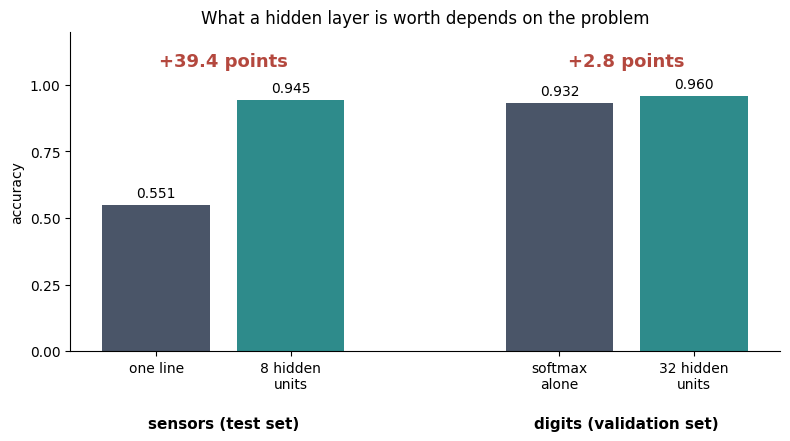

In [9]:
units = make_acceptance_test()
X = units[["gain_offset_db", "phase_offset_deg"]].values
y = units["accepted"].values
A_tr, A_te, b_tr, b_te = train_test_split(X, y, test_size=0.25, stratify=y,
                                          random_state=9101)
scaler = StandardScaler().fit(A_tr)
A_tr, A_te = scaler.transform(A_tr), scaler.transform(A_te)
sensor_line = LogisticRegression().fit(A_tr, b_tr).score(A_te, b_te)
sensor_net = np.mean([MLPClassifier(hidden_layer_sizes=(8,), max_iter=3000,
                                    random_state=s).fit(A_tr, b_tr).score(A_te, b_te)
                      for s in range(5)])
digit_line = digit_table.iloc[0]["validation accuracy"]
digit_net = digit_table.iloc[1]["validation accuracy"]

sensor_gain = 100 * (sensor_net - sensor_line)
digit_gain = 100 * (digit_net - digit_line)
print(f"sensors: one line {sensor_line:.4f}, 8 hidden units {sensor_net:.4f}  "
      f"-> the hidden layer is worth {sensor_gain:.1f} points")
print(f"digits : softmax alone {digit_line:.4f}, 32 hidden units {digit_net:.4f}  "
      f"-> the hidden layer is worth {digit_gain:.1f} points")

fig, ax = plt.subplots(figsize=(8.0, 4.6))
positions = np.array([0, 1, 3, 4])
values = [sensor_line, sensor_net, digit_line, digit_net]
colours = [SLATE, TEAL, SLATE, TEAL]
bars = ax.bar(positions, values, color=colours, width=0.8)
ax.bar_label(bars, labels=[f"{v:.3f}" for v in values], padding=3, fontsize=10)
for left, gain in ((0, sensor_gain), (3, digit_gain)):
    ax.annotate(f"+{gain:.1f} points", xy=(left + 0.5, 1.07), ha="center",
                fontsize=13, weight="bold", color=RUST)
ax.set_xticks(positions)
ax.set_xticklabels(["one line", "8 hidden\nunits", "softmax\nalone", "32 hidden\nunits"])
ax.text(0.5, -0.24, "sensors (test set)", ha="center", transform=ax.get_xaxis_transform(),
        fontsize=11, weight="bold")
ax.text(3.5, -0.24, "digits (validation set)", ha="center",
        transform=ax.get_xaxis_transform(), fontsize=11, weight="bold")
ax.set_ylim(0, 1.2); ax.set_yticks([0, 0.25, 0.5, 0.75, 1.0])
ax.set_ylabel("accuracy")
ax.set_title("What a hidden layer is worth depends on the problem")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(FIGURES / "hidden_layer_worth.png", dpi=150, bbox_inches="tight")
plt.show()

Is 2.8 a property of the digits, or of this particular split of them? Draw a
different train/validation split and three other starting points, and measure
the same gap again.

In [10]:
X_tr2, y_tr2, X_va2, y_va2, _, _ = load_digit_images(seed=1234)


def gap_run(hidden, seed):
    keras.utils.set_random_seed(seed)
    m = keras.Sequential([keras.Input(shape=(64,))]
                         + [layers.Dense(u, activation="relu") for u in hidden]
                         + [layers.Dense(TRUE_N_CLASSES, activation="softmax")])
    m.compile(optimizer=keras.optimizers.Adam(1e-3),
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    m.fit(X_tr2, y_tr2, epochs=60, batch_size=32, verbose=0)
    return m.evaluate(X_va2, y_va2, verbose=0)[1]


alone2 = np.mean([gap_run([], s) for s in (10, 11, 12)])
hidden2 = np.mean([gap_run([32], s) for s in (10, 11, 12)])
print(f"another split: softmax alone {alone2:.4f}, 32 hidden units {hidden2:.4f}  "
      f"-> {100 * (hidden2 - alone2):.1f} points")

another split: softmax alone 0.9167, 32 hidden units 0.9639  -> 4.7 points


The exact figure moves with the split: 2.8 points on one, the value printed
above on another. Its size does not: **a few points on the digits, about 39 on
the sensors**. On the sensors the answer depends on the two
offsets *together*: a sensor passes when the pair is close to the centre, which
no weighted sum of the two can express. On the digits each pixel pushes the
answer more or less on its own (dark here means a 0 is likely, dark there a 1),
and a weighted sum of pixels already gets most of the way.

**A hidden layer is worth adding when the answer depends on inputs in
combination.** Try the linear model first; the size of the gap is the
measurement that tells you whether a network was needed.

## Summary

- Keras builds a network as a list of layers; `compile` chooses the loss and the
  optimiser; `fit` trains it in mini-batches, one epoch per pass over the data.
- Softmax turns the output layer's ten scores into ten probabilities that add
  up to 1.
- One hidden layer took the digits from about 0.93 to about 0.96, 2.8 points
  (a few points on another split); on the sensors the same idea was worth
  about 39.